<a href="https://colab.research.google.com/github/RohanSNikam/Logistics-Delivery-Time-Analysis/blob/main/notebooks/logistics_delivery_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Logistics Delivery Time Analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Project started successfully!")
print("Ready to explore logistics delivery data.")

Project started successfully!
Ready to explore logistics delivery data.


In [3]:
from google.colab import files

uploaded = files.upload()

Saving logistics_delivery_data.csv to logistics_delivery_data.csv


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data = pd.read_csv("logistics_delivery_data.csv")

print("Dataset loaded successfully!")
print(data.head())


Dataset loaded successfully!
  order_id  order_date  distance_km traffic_level weather vehicle_type  \
0  ORD0001  2026-01-17           61        Medium   Clear          Van   
1  ORD0002  2026-05-20          328          High   Clear        Truck   
2  ORD0003  2026-04-28          482          High   Clear          Van   
3  ORD0004  2026-03-20          435        Medium   Clear          Van   
4  ORD0005  2026-03-19          140        Medium   Clear        Truck   

   order_value_inr  promised_delivery_minutes  actual_delivery_minutes  \
0             4899                        115                       95   
1            12673                        372                      401   
2              722                        676                      689   
3             6807                        617                      607   
4            12055                        180                      186   

   delivery_cost_inr delivery_status  
0             137.09         On Time  
1  

In [5]:

# 1. Check the number of rows and columns
print("Dataset shape:", data.shape)

# 2. Display all column names
print("\nColumn names:")
print(data.columns.tolist())

# 3. Check data types and missing values
print("\nDataset information:")
data.info()

# 4. Count missing values in each column
print("\nMissing values:")
print(data.isnull().sum())


Dataset shape: (500, 11)

Column names:
['order_id', 'order_date', 'distance_km', 'traffic_level', 'weather', 'vehicle_type', 'order_value_inr', 'promised_delivery_minutes', 'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   order_id                   500 non-null    object 
 1   order_date                 500 non-null    object 
 2   distance_km                500 non-null    int64  
 3   traffic_level              492 non-null    object 
 4   weather                    495 non-null    object 
 5   vehicle_type               500 non-null    object 
 6   order_value_inr            500 non-null    int64  
 7   promised_delivery_minutes  500 non-null    int64  
 8   actual_delivery_minutes    500 non-null    int64  
 9   delivery_co

In [6]:

# Step 4: Check duplicate records
print("Duplicate rows:", data.duplicated().sum())

# Check duplicate order IDs
print("Duplicate order IDs:", data["order_id"].duplicated().sum())

# Check missing values
print("\nMissing values before cleaning:")
print(data.isnull().sum())


Duplicate rows: 0
Duplicate order IDs: 0

Missing values before cleaning:
order_id                     0
order_date                   0
distance_km                  0
traffic_level                8
weather                      5
vehicle_type                 0
order_value_inr              0
promised_delivery_minutes    0
actual_delivery_minutes      0
delivery_cost_inr            4
delivery_status              0
dtype: int64


In [7]:

# Step 5: Create a cleaned copy of the dataset
cleaned_data = data.copy()

# Fill missing categorical values
cleaned_data["traffic_level"] = (
    cleaned_data["traffic_level"].fillna("Unknown")
)

cleaned_data["weather"] = (
    cleaned_data["weather"].fillna("Unknown")
)

# Fill missing delivery costs using the median
median_cost = cleaned_data["delivery_cost_inr"].median()

cleaned_data["delivery_cost_inr"] = (
    cleaned_data["delivery_cost_inr"].fillna(median_cost)
)

# Check missing values after cleaning
print("Missing values after cleaning:")
print(cleaned_data.isnull().sum())

print("\nDataset shape after cleaning:", cleaned_data.shape)
print("\nMedian delivery cost used:", median_cost)


Missing values after cleaning:
order_id                     0
order_date                   0
distance_km                  0
traffic_level                0
weather                      0
vehicle_type                 0
order_value_inr              0
promised_delivery_minutes    0
actual_delivery_minutes      0
delivery_cost_inr            0
delivery_status              0
dtype: int64

Dataset shape after cleaning: (500, 11)

Median delivery cost used: 465.21000000000004


In [8]:

# Step 6: Calculate logistics KPIs

# Calculate delivery delay in minutes
cleaned_data["delay_minutes"] = (
    cleaned_data["actual_delivery_minutes"]
    - cleaned_data["promised_delivery_minutes"]
)

# KPI 1: Average actual delivery time
average_delivery_time = cleaned_data["actual_delivery_minutes"].mean()

# KPI 2: Average delivery delay
average_delay = cleaned_data["delay_minutes"].mean()

# KPI 3: On-time delivery rate
on_time_orders = (
    cleaned_data["actual_delivery_minutes"]
    <= cleaned_data["promised_delivery_minutes"]
).sum()

total_orders = len(cleaned_data)

on_time_rate = (on_time_orders / total_orders) * 100

# Display results
print("Total orders:", total_orders)
print("Average delivery time:", round(average_delivery_time, 2), "minutes")
print("Average delivery delay:", round(average_delay, 2), "minutes")
print("On-time delivery rate:", round(on_time_rate, 2), "%")


Total orders: 500
Average delivery time: 422.44 minutes
Average delivery delay: 2.45 minutes
On-time delivery rate: 47.0 %


delivery_status
Delayed    265
On Time    235
Name: count, dtype: int64


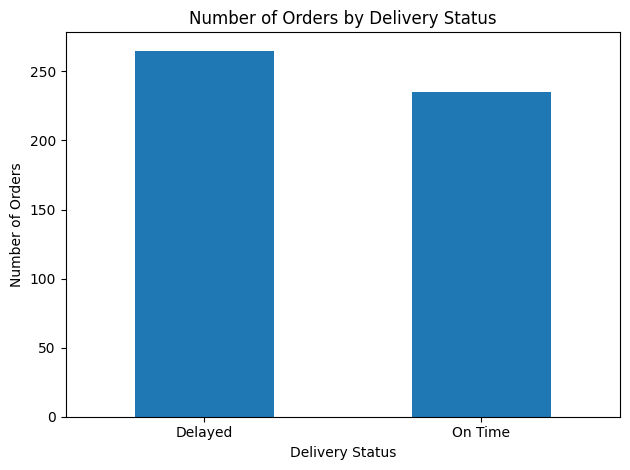

In [9]:

# Step 8: Count delivery status
status_counts = cleaned_data["delivery_status"].value_counts()

print(status_counts)

# Create a bar chart
status_counts.plot(kind="bar")

plt.title("Number of Orders by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [10]:

# Step 9: Analyze delays by traffic level

traffic_analysis = cleaned_data.groupby("traffic_level").agg(
    total_orders=("order_id", "count"),
    average_delay=("delay_minutes", "mean"),
    average_delivery_time=("actual_delivery_minutes", "mean")
).round(2)

print(traffic_analysis)


               total_orders  average_delay  average_delivery_time
traffic_level                                                    
High                    133          25.12                 465.82
Low                     155         -18.52                 410.09
Medium                  204           3.22                 408.52
Unknown                   8          12.62                 295.50


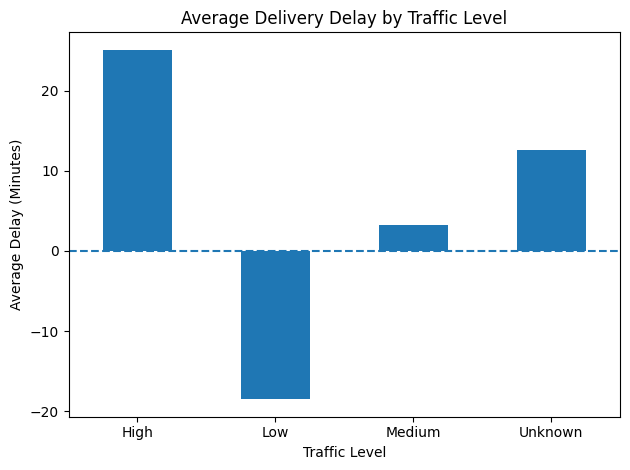

In [11]:

# Step 10: Plot average delivery delay by traffic level

traffic_analysis["average_delay"].plot(kind="bar")

plt.title("Average Delivery Delay by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Average Delay (Minutes)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [12]:

# Step 11: Analyze delivery performance by vehicle type

vehicle_analysis = cleaned_data.groupby("vehicle_type").agg(
    total_orders=("order_id", "count"),
    average_delivery_time=("actual_delivery_minutes", "mean"),
    average_delay=("delay_minutes", "mean")
).round(2)

print(vehicle_analysis)


              total_orders  average_delivery_time  average_delay
vehicle_type                                                    
Bike                   124                 658.51          -0.27
Truck                  136                 299.04           5.32
Van                    240                 370.40           2.24


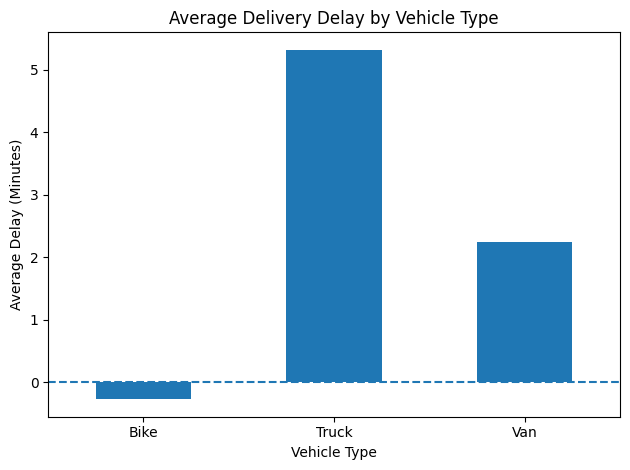

In [13]:

# Step 12: Compare average delivery delay by vehicle

vehicle_analysis["average_delay"].plot(kind="bar")

plt.title("Average Delivery Delay by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delay (Minutes)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [14]:

# Step 13: Analyze delivery performance by weather

weather_analysis = cleaned_data.groupby("weather").agg(
    total_orders=("order_id", "count"),
    average_delivery_time=("actual_delivery_minutes", "mean"),
    average_delay=("delay_minutes", "mean")
).round(2)

print(weather_analysis)


         total_orders  average_delivery_time  average_delay
weather                                                    
Clear             323                 405.67          -4.49
Rain              128                 449.03          10.38
Storm              44                 472.07          28.59
Unknown             5                 388.40          18.00


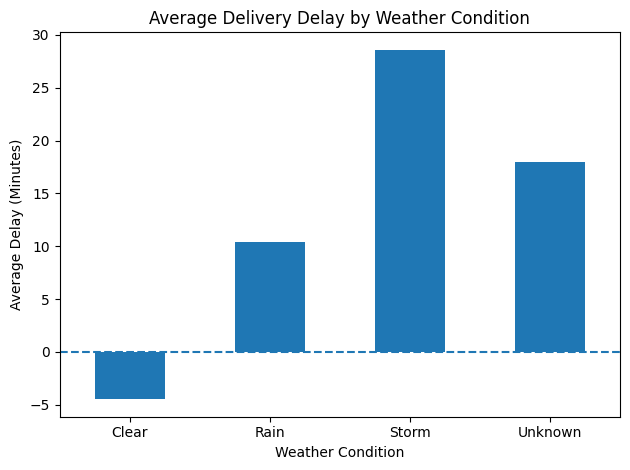

In [15]:

# Compare average delivery delay by weather

weather_analysis["average_delay"].plot(kind="bar")

plt.title("Average Delivery Delay by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delay (Minutes)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [16]:

# Step 14: Analyze delivery performance by distance

# Group delivery distances into categories
cleaned_data["distance_category"] = pd.cut(
    cleaned_data["distance_km"],
    bins=[0, 100, 200, 300, 400, float("inf")],
    labels=["0-100 km", "101-200 km", "201-300 km",
            "301-400 km", "Above 400 km"]
)

# Calculate delivery performance for each distance category
distance_analysis = cleaned_data.groupby(
    "distance_category", observed=False
).agg(
    total_orders=("order_id", "count"),
    average_delivery_time=("actual_delivery_minutes", "mean"),
    average_delay=("delay_minutes", "mean")
).round(2)

print(distance_analysis)


                   total_orders  average_delivery_time  average_delay
distance_category                                                    
0-100 km                    105                 109.59          -1.25
101-200 km                   79                 254.68           3.19
201-300 km                  107                 412.06           2.16
301-400 km                  104                 546.17           8.03
Above 400 km                105                 749.54           0.38


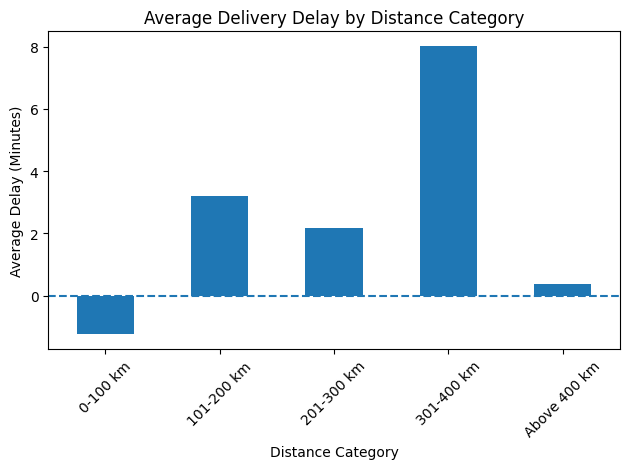

In [17]:

# Compare average delivery delay by distance

distance_analysis["average_delay"].plot(kind="bar")

plt.title("Average Delivery Delay by Distance Category")
plt.xlabel("Distance Category")
plt.ylabel("Average Delay (Minutes)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [18]:

# Step 15: Analyze delivery cost and order value

cost_analysis = cleaned_data.agg(
    total_orders=("order_id", "count"),
    average_delivery_cost=("delivery_cost_inr", "mean"),
    median_delivery_cost=("delivery_cost_inr", "median"),
    average_order_value=("order_value_inr", "mean")
).round(2)

print(cost_analysis)


                       order_id  delivery_cost_inr  order_value_inr
total_orders              500.0                NaN              NaN
average_delivery_cost       NaN             475.11              NaN
median_delivery_cost        NaN             465.21              NaN
average_order_value         NaN                NaN           7265.2


In [19]:

# Compare delivery cost by vehicle type

vehicle_cost = cleaned_data.groupby("vehicle_type").agg(
    total_orders=("order_id", "count"),
    average_delivery_cost=("delivery_cost_inr", "mean"),
    average_order_value=("order_value_inr", "mean")
).round(2)

print(vehicle_cost)


              total_orders  average_delivery_cost  average_order_value
vehicle_type                                                          
Bike                   124                 334.86              6562.73
Truck                  136                 588.62              7795.66
Van                    240                 483.25              7327.55


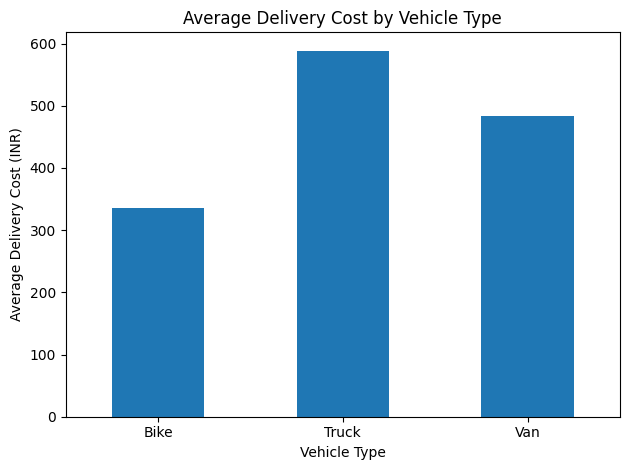

In [20]:

vehicle_cost["average_delivery_cost"].plot(kind="bar")

plt.title("Average Delivery Cost by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Delivery Cost (INR)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [21]:

# Step 16: Delivery status by traffic level

traffic_status = pd.crosstab(
    cleaned_data["traffic_level"],
    cleaned_data["delivery_status"]
)

print(traffic_status)


delivery_status  Delayed  On Time
traffic_level                    
High                 116       17
Low                   22      133
Medium               121       83
Unknown                6        2


In [23]:

# Step 17: Calculate delay percentage by traffic level

traffic_delay_percentage = (
    traffic_status["Delayed"] / traffic_status.sum(axis=1) * 100
).round(2)

print("Delay percentage by traffic level:")
print(traffic_delay_percentage)


Delay percentage by traffic level:
traffic_level
High       87.22
Low        14.19
Medium     59.31
Unknown    75.00
dtype: float64


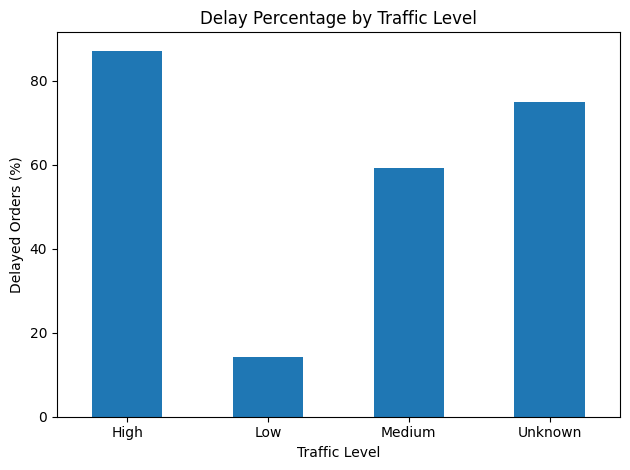

In [24]:

traffic_delay_percentage.plot(kind="bar")

plt.title("Delay Percentage by Traffic Level")
plt.xlabel("Traffic Level")
plt.ylabel("Delayed Orders (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [26]:

# Step 18: Analyze delivery delay by distance category

distance_status = pd.crosstab(
    cleaned_data["distance_category"],
    cleaned_data["delivery_status"]
)

print(distance_status)


delivery_status    Delayed  On Time
distance_category                  
0-100 km                43       62
101-200 km              44       35
201-300 km              60       47
301-400 km              66       38
Above 400 km            52       53


In [27]:

# Step 18.1: Calculate delay percentage by distance

distance_delay_percentage = (
    distance_status["Delayed"] / distance_status.sum(axis=1)
) * 100

distance_delay_percentage = distance_delay_percentage.round(2)

print(distance_delay_percentage)


distance_category
0-100 km        40.95
101-200 km      55.70
201-300 km      56.07
301-400 km      63.46
Above 400 km    49.52
dtype: float64


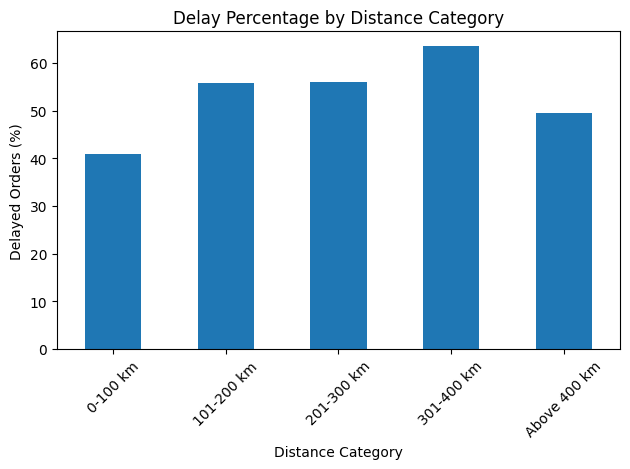

In [28]:

# Step 18.2: Visualize delay percentage by distance

distance_delay_percentage.plot(kind="bar")

plt.title("Delay Percentage by Distance Category")
plt.xlabel("Distance Category")
plt.ylabel("Delayed Orders (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [31]:

# Step 19: Check package-related columns

print(cleaned_data.columns.tolist())


# Step 19: Check order value data

print(cleaned_data["order_value_inr"].describe())



['order_id', 'order_date', 'distance_km', 'traffic_level', 'weather', 'vehicle_type', 'order_value_inr', 'promised_delivery_minutes', 'actual_delivery_minutes', 'delivery_cost_inr', 'delivery_status', 'delay_minutes', 'distance_category']
count      500.000000
mean      7265.202000
std       4243.013178
min        246.000000
25%       4028.250000
50%       6834.000000
75%      11068.750000
max      14997.000000
Name: order_value_inr, dtype: float64


In [32]:

# Step 19.1: Create order value categories

cleaned_data["order_value_category"] = pd.cut(
    cleaned_data["order_value_inr"],
    bins=[-1, 500, 1000, 2000, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)

print(cleaned_data[
    ["order_value_inr", "order_value_category"]
].head(10))


   order_value_inr order_value_category
0             4899            Very High
1            12673            Very High
2              722               Medium
3             6807            Very High
4            12055            Very High
5            14304            Very High
6             3921            Very High
7             9832            Very High
8             3007            Very High
9             1915                 High


In [33]:

# Step 19.1: Create order value categories

cleaned_data["order_value_category"] = pd.cut(
    cleaned_data["order_value_inr"],
    bins=[-1, 500, 1000, 2000, float("inf")],
    labels=["Low", "Medium", "High", "Very High"]
)

print(cleaned_data[
    ["order_value_inr", "order_value_category"]
].head(10))


   order_value_inr order_value_category
0             4899            Very High
1            12673            Very High
2              722               Medium
3             6807            Very High
4            12055            Very High
5            14304            Very High
6             3921            Very High
7             9832            Very High
8             3007            Very High
9             1915                 High


In [34]:

# Step 19.2: Analyze delivery performance by order value

order_value_analysis = cleaned_data.groupby(
    "order_value_category",
    observed=False
).agg(
    total_orders=("order_id", "count"),
    average_delay=("delay_minutes", "mean"),
    average_delivery_time=("actual_delivery_minutes", "mean"),
    average_delivery_cost=("delivery_cost_inr", "mean")
).round(2)

print(order_value_analysis)


                      total_orders  average_delay  average_delivery_time  \
order_value_category                                                       
Low                              9           3.67                 484.22   
Medium                          23          -6.48                 413.52   
High                            33          -0.55                 438.76   
Very High                      435           3.13                 420.40   

                      average_delivery_cost  
order_value_category                         
Low                                  501.18  
Medium                               458.13  
High                                 466.94  
Very High                            476.09  


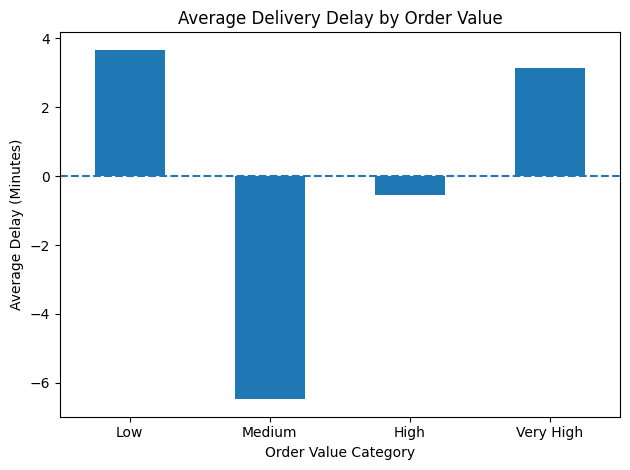

In [35]:

# Step 19.3: Visualize average delay by order value

order_value_analysis["average_delay"].plot(kind="bar")

plt.title("Average Delivery Delay by Order Value")
plt.xlabel("Order Value Category")
plt.ylabel("Average Delay (Minutes)")
plt.axhline(y=0, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [36]:

# Step 20: Check order dates

print(cleaned_data["order_date"].head())
print(cleaned_data["order_date"].dtype)


0    2026-01-17
1    2026-05-20
2    2026-04-28
3    2026-03-20
4    2026-03-19
Name: order_date, dtype: object
object


In [37]:

# Convert order_date into datetime format

cleaned_data["order_date"] = pd.to_datetime(
    cleaned_data["order_date"],
    errors="coerce"
)

print(cleaned_data["order_date"].dtype)


datetime64[ns]


In [38]:

# Step 20.2: Average delay for each date

daily_analysis = cleaned_data.groupby(
    cleaned_data["order_date"].dt.date
).agg(
    total_orders=("order_id", "count"),
    average_delay=("delay_minutes", "mean")
).round(2)

print(daily_analysis.head(10))


            total_orders  average_delay
order_date                             
2026-01-01             1         -12.00
2026-01-02             3          25.67
2026-01-03             1         -17.00
2026-01-04             5         -14.80
2026-01-05             4          -0.25
2026-01-06             2          12.00
2026-01-07             3          -5.33
2026-01-08             2          10.50
2026-01-09             2         -12.50
2026-01-11             1         -10.00


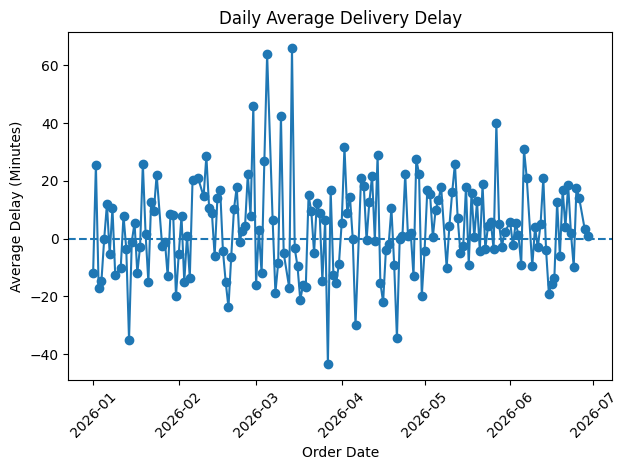

In [39]:

# Step 20.3: Visualize daily delivery delays

daily_analysis["average_delay"].plot(kind="line", marker="o")

plt.title("Daily Average Delivery Delay")
plt.xlabel("Order Date")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=45)
plt.axhline(y=0, linestyle="--")
plt.tight_layout()
plt.show()
